# Chapter 4 — Introduction to Neural Learning: Gradient Descent
### Reproduction & Theoretical Deep-Dive — *grokking Deep Learning* (Manning)

Chapter 3 produced predictions with hand-picked weights. This chapter covers the remaining two steps
of **Predict → Compare → Learn**:

- **Compare** — measure how wrong a prediction is (the **error**).
- **Learn** — use that error to change the weight so the next prediction is better.

We study the simplest possible case — **one input, one weight, one training example** — and look at two
learning methods: the naive **hot and cold learning** and the real thing, **gradient descent**.

> **Note on the examples.** The numbers below are my own (input 1.5, target 3.0). The ideas and order
> follow the chapter: error → hot-and-cold → derivative/gradient → update rule → learning rate.

**Roadmap**
1. Measuring error (why squared?)
2. Hot and cold learning (and its limits)
3. The gradient: direction and amount, derived and verified
4. Gradient descent
5. The learning rate $\alpha$: too small, just right, too big
6. From one example to many

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)
np.set_printoptions(precision=4, suppress=True)

x, target = 1.5, 3.0            # one training example: input and the answer we want

def predict(x, w):
    return x * w

def squared_error(pred, target):
    return (pred - target) ** 2

w = 0.5
pred = predict(x, w)
print(f"w = {w}: prediction = {pred}, target = {target}, squared error = {squared_error(pred, target)}")

w = 0.5: prediction = 0.75, target = 3.0, squared error = 5.0625


## 1. Measuring error

**Compare** means turning "how wrong?" into a single number. For one example the standard choice is the
**squared error**

$$E = (\hat y - y)^2 = (x\,w - y)^2 .$$

Why square the difference $\hat y - y$ rather than use it directly or take its absolute value?

1. **Always non-negative.** Over- and under-shooting both count as "bad" and cannot cancel each other out.
2. **Big mistakes hurt more.** An error of 4 costs 16, an error of 1 costs 1 — the learner focuses on the worst misses first.
3. **Smooth.** The squared error has a well-behaved slope everywhere (the absolute value has a sharp kink at 0),
   which is what lets us use calculus in Section 3.

Since $\hat y = xw$, for fixed $x$ and $y$ the error is a function of the **weight alone**. Plotting it
shows the "landscape" that learning has to explore.

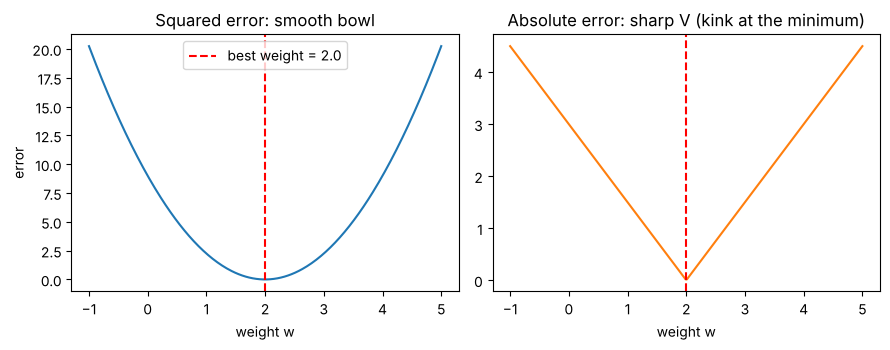

In [2]:
ws = np.linspace(-1, 5, 300)
sq = squared_error(predict(x, ws), target)
ab = np.abs(predict(x, ws) - target)
w_star = target / x

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].plot(ws, sq); axes[0].axvline(w_star, color='red', ls='--', label=f'best weight = {w_star}')
axes[0].set_title('Squared error: smooth bowl'); axes[0].set_xlabel('weight w'); axes[0].set_ylabel('error'); axes[0].legend()
axes[1].plot(ws, ab, color='tab:orange'); axes[1].axvline(w_star, color='red', ls='--')
axes[1].set_title('Absolute error: sharp V (kink at the minimum)'); axes[1].set_xlabel('weight w')
plt.tight_layout()
plt.savefig('outputs/error_curves.png', dpi=110)
plt.show()

**Reading the output.** The squared error is a smooth parabola whose lowest point (error = 0) is at
$w^\* = y/x = 2$. The goal of learning is simply to **slide $w$ to the bottom of the bowl** without being told where the bottom is.

## 2. Hot and cold learning

The most naive idea: *try nudging the weight both ways and keep whichever is better.*

1. Compute the error if $w$ is increased by a fixed `step`.
2. Compute the error if $w$ is decreased by `step`.
3. Move to whichever side has the lower error. Repeat.

It works like the children's game "hot and cold": you only learn whether a move got you closer.

In [3]:
def hot_and_cold(w_start, step, n_iter):
    w = w_start
    history = [w]
    for _ in range(n_iter):
        err_up   = squared_error(predict(x, w + step), target)
        err_down = squared_error(predict(x, w - step), target)
        w = w + step if err_up < err_down else w - step
        history.append(w)
    return np.array(history)

hc = hot_and_cold(w_start=0.5, step=0.07, n_iter=40)
hc_err = squared_error(predict(x, hc), target)

print("iter |   w    |  error")
for i in list(range(0, 4)) + list(range(20, 26)) + [38, 39, 40]:
    print(f"{i:4d} | {hc[i]:6.3f} | {hc_err[i]:.4f}")

iter |   w    |  error
   0 |  0.500 | 5.0625
   1 |  0.570 | 4.6010
   2 |  0.640 | 4.1616
   3 |  0.710 | 3.7442
  20 |  1.900 | 0.0225
  21 |  1.970 | 0.0020
  22 |  2.040 | 0.0036
  23 |  1.970 | 0.0020
  24 |  2.040 | 0.0036
  25 |  1.970 | 0.0020
  38 |  2.040 | 0.0036
  39 |  1.970 | 0.0020
  40 |  2.040 | 0.0036


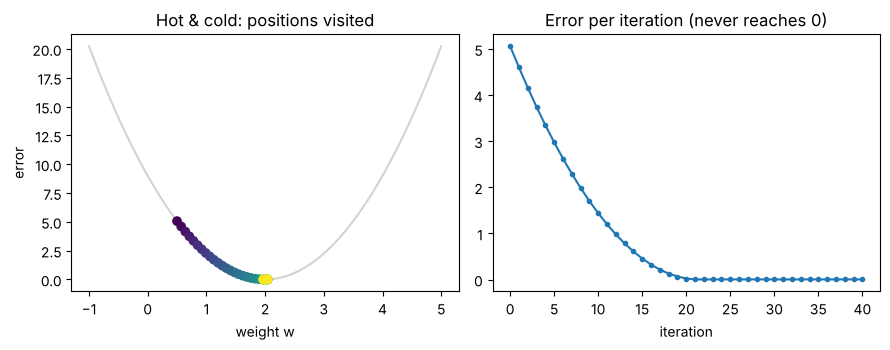

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].plot(ws, sq, color='lightgray')
axes[0].scatter(hc, hc_err, c=np.arange(len(hc)), cmap='viridis', zorder=3)
axes[0].set_title('Hot & cold: positions visited'); axes[0].set_xlabel('weight w'); axes[0].set_ylabel('error')
axes[1].plot(hc_err, marker='o', ms=3)
axes[1].set_title('Error per iteration (never reaches 0)'); axes[1].set_xlabel('iteration')
plt.tight_layout()
plt.savefig('outputs/hot_and_cold.png', dpi=110)
plt.show()

**Reading the output.** The weight marches steadily towards 2 and then **jitters back and forth around
it** (≈1.97 ↔ 2.04): with a fixed step it can hop over the minimum but never land exactly on it. Hot and cold has three weaknesses:

- **Wasteful** — each update needs two extra predictions, and with thousands of weights that multiplies enormously.
- **Fixed step size** — it moves just as far when it is almost at the bottom as when it is far away, so it cannot settle.
- **Only a direction, no amount** — it learns nothing about *how far* to go.

We need a method that reads the direction **and** the amount of the correction straight from the error.

## 3. The gradient: direction *and* amount

The slope of the error curve at the current weight provides both:

- **Sign** of the slope → which way the error increases (so we should move the other way).
- **Size** of the slope → how steep it is: steep far from the minimum, flat close to it.

That slope is the **derivative** $\dfrac{dE}{dw}$ (for many weights: the **gradient**). With
$e = xw - y$ (the signed error, called the *delta* in the book) and $E = e^2$, the chain rule gives

$$\frac{dE}{dw} = \frac{dE}{de}\cdot\frac{de}{dw} = 2e \cdot x = 2x\,(xw - y).$$

Let me verify this formula against a purely numerical estimate of the slope,
$\dfrac{E(w+h)-E(w-h)}{2h}$ with a tiny $h$. If the algebra is right they must agree.

In [5]:
def gradient(x, w, target):
    delta = predict(x, w) - target          # signed 'pure' error
    return 2 * delta * x                    # dE/dw

def numerical_gradient(w, h=1e-6):
    return (squared_error(predict(x, w + h), target) - squared_error(predict(x, w - h), target)) / (2 * h)

print("   w   | analytic | numerical")
for w_test in [0.5, 1.0, 2.0, 3.5]:
    print(f"{w_test:5.2f}  | {gradient(x, w_test, target):8.4f} | {numerical_gradient(w_test):8.4f}")

   w   | analytic | numerical
 0.50  |  -6.7500 |  -6.7500
 1.00  |  -4.5000 |  -4.5000
 2.00  |   0.0000 |   0.0000
 3.50  |   6.7500 |   6.7500


**Reading the output.**
- At $w=0.5$ the slope is **negative** ($-6.75$): the error falls as $w$ grows, so $w$ should go **up**.
- At $w=3.5$ the slope is **positive**: the error rises with $w$, so $w$ should go **down**.
- At $w=2$ the slope is **0**: we are at the bottom.

Analytic and numerical values agree, so the formula is right.

## 4. Gradient descent

To go downhill, step **against** the slope, scaled by a small positive constant $\alpha$ (the
**learning rate**):

$$w \;\leftarrow\; w - \alpha\,\frac{dE}{dw} \;=\; w - \alpha\cdot 2x\,(xw - y)$$

Notice how much better behaved this is than hot and cold:

- the **sign** of the gradient chooses the direction automatically;
- the **magnitude** of the gradient makes steps large when far away and shrink to zero near the minimum,
  because the curve flattens — so it can settle;
- one gradient evaluation replaces the two extra predictions.

(Many texts write the update with the factor 2 absorbed into $\alpha$; it only rescales the learning rate.)

In [6]:
def gradient_descent(w_start, alpha, n_iter):
    w = w_start
    ws_, errs_ = [w], [squared_error(predict(x, w), target)]
    for _ in range(n_iter):
        w = w - alpha * gradient(x, w, target)
        ws_.append(w)
        errs_.append(squared_error(predict(x, w), target))
    return np.array(ws_), np.array(errs_)

gd_w, gd_err = gradient_descent(w_start=0.5, alpha=0.1, n_iter=12)

print("iter |    w    |  error   | gradient")
for i, (wi, ei) in enumerate(zip(gd_w, gd_err)):
    print(f"{i:4d} | {wi:7.4f} | {ei:8.5f} | {gradient(x, wi, target):8.4f}")

iter |    w    |  error   | gradient
   0 |  0.5000 |  5.06250 |  -6.7500
   1 |  1.1750 |  1.53141 |  -3.7125
   2 |  1.5463 |  0.46325 |  -2.0419
   3 |  1.7504 |  0.14013 |  -1.1230
   4 |  1.8627 |  0.04239 |  -0.6177
   5 |  1.9245 |  0.01282 |  -0.3397
   6 |  1.9585 |  0.00388 |  -0.1868
   7 |  1.9772 |  0.00117 |  -0.1028
   8 |  1.9874 |  0.00035 |  -0.0565
   9 |  1.9931 |  0.00011 |  -0.0311
  10 |  1.9962 |  0.00003 |  -0.0171
  11 |  1.9979 |  0.00001 |  -0.0094
  12 |  1.9989 |  0.00000 |  -0.0052


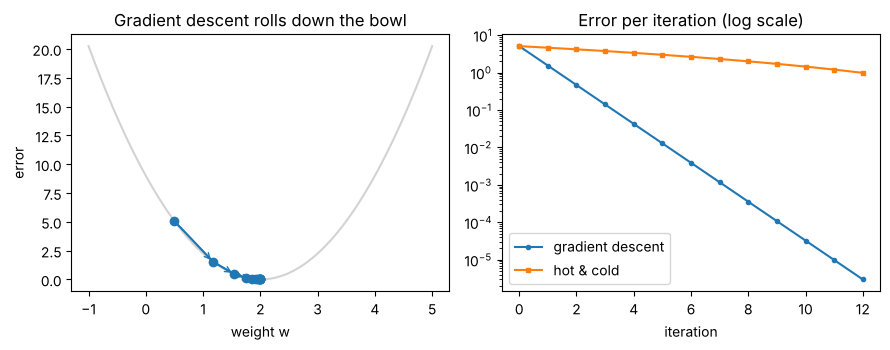

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].plot(ws, sq, color='lightgray')
axes[0].plot(gd_w, gd_err, marker='o', color='tab:blue')
for i in range(len(gd_w) - 1):
    axes[0].annotate('', xy=(gd_w[i + 1], gd_err[i + 1]), xytext=(gd_w[i], gd_err[i]),
                     arrowprops=dict(arrowstyle='->', color='tab:blue'))
axes[0].set_title('Gradient descent rolls down the bowl'); axes[0].set_xlabel('weight w'); axes[0].set_ylabel('error')
axes[1].semilogy(gd_err, marker='o', ms=3, label='gradient descent')
axes[1].semilogy(hc_err[:13], marker='s', ms=3, label='hot & cold')
axes[1].set_title('Error per iteration (log scale)'); axes[1].set_xlabel('iteration'); axes[1].legend()
plt.tight_layout()
plt.savefig('outputs/gradient_descent.png', dpi=110)
plt.show()

**Reading the output.** Steps are big at first and get smaller automatically as the slope flattens, and the
error shrinks by a constant factor each iteration (a straight line on the log plot). Compared with the
hot-and-cold curve, it homes in on the minimum far faster and does not jitter.

## 5. The learning rate $\alpha$

$\alpha$ decides how far to move along the slope. For this model we can analyse exactly what happens. Let
$w^\* = y/x$ be the optimum. Because $xw - y = x\,(w - w^\*)$,

$$w_{t+1} - w^\* = (w_t - w^\*) - 2\alpha x^2 (w_t - w^\*) = \underbrace{\left(1 - 2\alpha x^2\right)}_{c}\,(w_t - w^\*).$$

So the distance to the optimum is multiplied by $c = 1 - 2\alpha x^2$ at every step:

| value of $c$ | behaviour |
|---|---|
| $0 < c < 1$ | smooth convergence (smaller $\alpha$ → $c$ closer to 1 → slow) |
| $c = 0$ | lands on the optimum in **one** step: $\alpha = 1/(2x^2)$ |
| $-1 < c < 0$ | overshoots the minimum each step, but the swings shrink: still converges |
| $c \le -1$ | **diverges**: the steps overshoot by more than the distance they travelled |

Converging requires $|c|<1$, i.e. $0 < \alpha < 1/x^2$. Let me confirm this with experiments.

alpha   | c = 1 - 2*alpha*x^2 | final error after 15 steps
 0.0100 |               0.955 | 1.272e+00
 0.1000 |               0.550 | 8.227e-08
 0.2222 |               0.000 | 0.000e+00
 0.4000 |              -0.800 | 6.267e-03
 0.5000 |              -1.250 | 4.089e+03


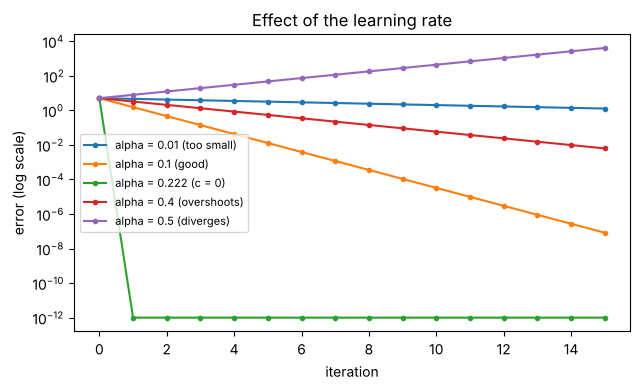

In [8]:
alphas = {'0.01 (too small)': 0.01, '0.1 (good)': 0.1, f'{1/(2*x**2):.3f} (c = 0)': 1/(2*x**2),
          '0.4 (overshoots)': 0.4, '0.5 (diverges)': 0.5}

plt.figure(figsize=(6.5, 4))
print("alpha   | c = 1 - 2*alpha*x^2 | final error after 15 steps")
for label, a in alphas.items():
    _, e = gradient_descent(0.5, a, 15)
    plt.semilogy(np.clip(e, 1e-12, None), marker='o', ms=3, label=f'alpha = {label}')
    print(f"{a:7.4f} | {1 - 2 * a * x**2:19.3f} | {e[-1]:.3e}")
plt.xlabel('iteration'); plt.ylabel('error (log scale)')
plt.title('Effect of the learning rate'); plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('outputs/learning_rates.png', dpi=110)
plt.show()

In [9]:
# Verify the theory: the ratio of successive distances to the optimum equals c
a = 0.1
traj, _ = gradient_descent(0.5, a, 6)
dist = np.abs(traj - target / x)
print("measured ratios :", dist[1:] / dist[:-1])
print("predicted |c|   :", abs(1 - 2 * a * x**2))

measured ratios : [0.55 0.55 0.55 0.55 0.55 0.55]
predicted |c|   : 0.55


**Reading the output.**
- $\alpha=0.01$ converges, but crawls ($c\approx0.955$).
- $\alpha=0.1$ converges quickly and smoothly.
- $\alpha=1/(2x^2)$ finishes in a single step (error ≈ 0, shown at the floor of the plot).
- $\alpha=0.4$ jumps from one side of the bowl to the other, but each jump is smaller.
- $\alpha=0.5$ makes the error **explode** — the classic sign of a learning rate that is too large.

The measured contraction ratio matches the formula, which confirms that the analysis is correct.
In real networks the "safe" range of $\alpha$ depends on the data and the model, so it must be tuned by experiment.

## 6. From one example to many

Real training uses a dataset $\{(x_i, y_i)\}_{i=1}^{N}$. Define the error as the **average**
squared error; its slope is the average of the individual slopes:

$$E(w)=\frac1N\sum_{i}(x_i w-y_i)^2\qquad
\frac{dE}{dw}=\frac{2}{N}\sum_i x_i\,(x_i w-y_i).$$

For a one-weight model there is a closed-form optimum, $w^\*=\sum x_i y_i / \sum x_i^2$, so we can check
whether gradient descent finds the same answer.

gradient descent weight : 2.0171
closed-form optimum     : 2.0171


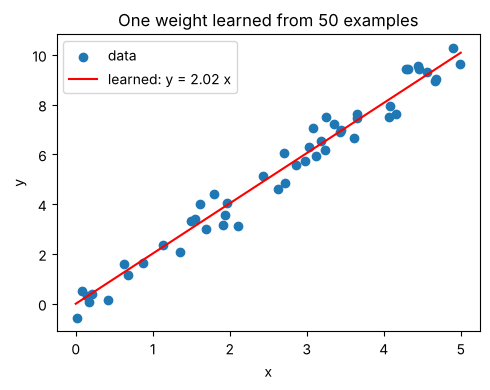

In [10]:
rng = np.random.default_rng(0)
xs = rng.uniform(0, 5, size=50)
ys = 2.0 * xs + rng.normal(0, 0.5, size=xs.size)      # true relationship y ≈ 2x with noise

def batch_gradient(w):
    return 2 * np.mean(xs * (xs * w - ys))

w = 0.0
for step in range(60):
    w -= 0.02 * batch_gradient(w)

w_closed_form = np.sum(xs * ys) / np.sum(xs ** 2)
print(f"gradient descent weight : {w:.4f}")
print(f"closed-form optimum     : {w_closed_form:.4f}")

plt.figure(figsize=(5, 4))
plt.scatter(xs, ys, label='data')
plt.plot([0, 5], [0, 5 * w], color='red', label=f'learned: y = {w:.2f} x')
plt.legend(); plt.xlabel('x'); plt.ylabel('y'); plt.title('One weight learned from 50 examples')
plt.tight_layout()
plt.savefig('outputs/one_weight_many_examples.png', dpi=110)
plt.show()

**Reading the output.** Gradient descent reaches the same weight as the exact formula, without using the
formula. The exact solution does not exist (or is impractical) for deep networks, but gradient descent still works —
which is why it is the engine of deep learning.

## Summary

| Idea | Formula / rule |
|---|---|
| Error (one example) | $E=(xw-y)^2$ |
| Slope of the error | $\dfrac{dE}{dw}=2x(xw-y)$ |
| Gradient descent update | $w\leftarrow w-\alpha\,\dfrac{dE}{dw}$ |
| Convergence condition (this model) | $0<\alpha<1/x^2$ |
| Best possible step in this model | $\alpha=1/(2x^2)$ |

- **Hot and cold** works but wastes predictions and cannot settle.
- **Gradient descent** uses the slope: direction from its sign, step size from its magnitude.
- The **learning rate** is a crucial hyper-parameter: too small is slow, too large diverges.
- Next, **Chapter 5**: the same recipe when there are many weights.